## Trying with the approach given in [Quantile Regression with Large Language Models for Price Prediction](https://arxiv.org/pdf/2506.06657?)

In [6]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
torch.cuda.empty_cache()

In [14]:
# load csv
df = pd.read_csv("../clean_data/train.csv")
ids = df['sample_id'].sort_values()
ids[ids == 279285]  # check index of id 279285

38945    279285
Name: sample_id, dtype: int64

In [17]:
df['image_path'] = "../images_resized/train_images/" + df['sample_id'].astype(str) + ".jpg"
# id = 201054
# df[df['sample_id'] == id]['Item Name'] + " " + df[df['sample_id'] == id]['Description']
df

,sample_id,image_link,Item Name,Description,Value,Unit,price,image_path
0,33127,https://m.media-amazon.com/images/I/51mo8htwTH...,"La Victoria Green Taco Sauce Mild, 12 Ounce (P...",NaN,72.00,fluid_ounce,4.890,../images_resized/train_images/33127.jpg
1,198967,https://m.media-amazon.com/images/I/71YtriIHAA...,"Salerno Cookies, The Original Butter Cookies, ...",Original Butter Cookies: Classic butter cookie...,32.00,ounce,13.120,../images_resized/train_images/198967.jpg
2,261251,https://m.media-amazon.com/images/I/51+PFEe-w-...,"Bear Creek Hearty Soup Bowl, Creamy Chicken wi...",Loaded with hearty long grain wild rice and ve...,11.40,ounce,1.970,../images_resized/train_images/261251.jpg
3,55858,https://m.media-amazon.com/images/I/41mu0HAToD...,Judee’s Blue Cheese Powder 11.25 oz - Gluten-F...,"Add to your favorite appetizers, dips & spread...",11.25,ounce,30.340,../images_resized/train_images/55858.jpg
4,292686,https://m.media-amazon.com/images/I/41sA037+Qv...,"kedem Sherry Cooking Wine, 12.7 Ounce - 12 per...",NaN,12.00,count,66.490,../images_resized/train_images/292686.jpg
...,...,...,...,...,...,...,...,...
74995,41424,https://m.media-amazon.com/images/I/81p9PcPsff...,"ICE BREAKERS Spearmint Sugar Free Mints Tins, ...",Contains eight (8) 1.5-ounce tins of ICE BREAK...,12.00,ounce,10.395,../images_resized/train_images/41424.jpg
74996,35537,https://m.media-amazon.com/images/I/51DDKoa+mb...,"Davidson's Organics, Vanilla Essence, 100-coun...",Vanilla Essence combines creamy carob with the...,100.00,count,35.920,../images_resized/train_images/35537.jpg
74997,249971,https://m.media-amazon.com/images/I/91R2XCcpUf...,Jolly Rancher Hard Candy - Blue Raspberry - 5 ...,NaN,80.00,ounce,50.330,../images_resized/train_images/249971.jpg
74998,188322,https://m.media-amazon.com/images/I/51W40YU98+...,Nescafe Dolce Gusto Capsules - CARAMEL MACCHIA...,Nescafe Dolce Gusto Caramel Latte Macchiato is...,16.00,count,15.275,../images_resized/train_images/188322.jpg


In [15]:
# resize all images to 224x224 and save to new folder
from PIL import Image
import os
os.makedirs("../images_resized/train_images", exist_ok=True)
# start from 279285 sample id
ids = ids[ids >= 279285]
for id in ids:
    try:
        img = Image.open("../images/train_images/" + str(id) + ".jpg")
        img = img.resize((224, 224))
        img.save("../images_resized/train_images/" + str(id) + ".jpg")
    except Exception as e:
        print(f"Error processing image {id}: {e}")

Error processing image 279285: [Errno 2] No such file or directory: '../images/train_images/279285.jpg'


In [4]:
# from embedding_utils import load_model_and_tokenizer, embed_texts, save_embeddings

# # Load tokenizer and model (uses GPU if available)
# tokenizer, model, device = load_model_and_tokenizer()

# # Prepare texts from `df` if available, otherwise use demo texts
# texts = None
# try:
#     _df = df  # expect `df` from earlier notebook cell
# except NameError:
#     _df = None

# texts = None
# # concat item_name and description for embedding
# if _df is not None and "Item Name" in _df.columns and "Description" in _df.columns:
#     # make string as name: name, description: description if both are present, else only name
#     texts = []
#     for _, row in _df.iterrows():
#         name = row["Item Name"].strip()
#         desc = row["Description"].strip() if pd.notna(row["Description"]) else ""
#         if name and desc:
#             texts.append(f"name: {name}, description: {desc}")
#         elif name:
#             texts.append(f"name: {name}")

# if not texts: 
#     texts = [
#         "Red cotton t-shirt with round neck",
#         "Wireless Bluetooth headphones with noise cancellation",
#         "Lightweight running shoes size 10",
#     ]

# # write texts to a file for record
# with open("texts_for_embedding.txt", "w") as f:
#     for text in texts:
#         f.write(text + "\n")

# print(f"Computing embeddings for {len(texts)} texts on device {device}...")
# embs = embed_texts(texts, tokenizer, model, device, batch_size=16, normalize=True)
# print("Embeddings shape:", embs.shape)

# out_path = "mistral_embeddings_from_notebook.npy"
# save_embeddings(out_path, embs)
# print("Saved embeddings to", out_path)

In [ ]:
from VLM_embedding_utils import load_vlm, get_embeddings_from_dataset, save_embeddings
# Load VLM model and processor (uses GPU if available)
# clear memory
torch.cuda.empty_cache()
vlm_model, vlm_processor, device = load_vlm()
# use the df to create image-text prompts and get embeddings for them 
dataset = []
if df is not None and "Item Name" in df.columns and "Description" in df.columns and "image_path" in df.columns:
    for _, row in df.iterrows():
        name = row["Item Name"].strip()
        desc = row["Description"].strip() if pd.notna(row["Description"]) else ""
        img_path = row["image_path"].strip() if pd.notna(row["image_path"]) else ""
        if name and img_path:
            prompt = f"name: {name}"
            if desc:
                prompt += f", description: {desc}"
            dataset.append({"img_path": img_path, "text": prompt})

print(dataset[:3])
print(f"Computing embeddings for {len(dataset)} image-text prompts on device {device}...")

# Get embeddings for all image-text prompts
emb = get_embeddings_from_dataset(
    dataset,
    vlm_processor,
    vlm_model
)
emb = torch.stack(emb)  # Convert list of tensors to a single tensor
print("Embedding shape:", emb.shape) # (n, dim)
print("Embedding (first 10 values):", emb[0][:10])

# Optionally save embeddings
save_embeddings(emb, "image_text_prompt_embedding.npy")

/home/project/miniconda3/envs/romitEEG/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.
Loading checkpoint shards: 100%|██████████| 5/5 [00:01<00:00,  3.88it/s]


In [ ]:
embs = np.load("mistral_embeddings_from_notebook.npy")

In [ ]:
# making new df with embeddings
emb_df = pd.DataFrame(embs)
emb_df["price"] = df["price"].values if df is not None and "price" in df.columns else np.nan
emb_df

,0,1,2,3,4,5,6,7,8,9,...,4087,4088,4089,4090,4091,4092,4093,4094,4095,price
0,0.001818,0.013635,-0.008984,-0.028418,-0.000732,0.002679,0.002971,0.009266,0.005524,0.002985,...,0.001104,-0.012453,0.054717,0.016499,0.085519,0.005633,-0.014988,-0.004963,-0.018402,4.890
1,0.011329,0.021465,0.013963,-0.010395,0.003786,0.007809,-0.000394,0.008718,0.000234,-0.007467,...,-0.007058,-0.013480,0.003303,0.011087,0.033739,0.013378,-0.022628,-0.009748,-0.007222,13.120
2,-0.003192,0.014954,0.001066,-0.021719,0.003289,0.015717,0.004753,0.007376,-0.004010,-0.009090,...,-0.013398,-0.018940,0.029279,0.011304,0.115187,0.004752,-0.006547,-0.002103,-0.012712,1.970
3,0.005722,0.012575,0.008872,-0.001760,0.004253,-0.002829,0.001492,0.006482,0.002473,-0.004765,...,-0.009016,-0.001922,0.000538,0.014662,0.086614,0.018846,0.001173,-0.008962,-0.003523,30.340
4,0.003313,0.025396,-0.000167,-0.025199,0.002554,-0.005938,-0.001568,0.005987,-0.006320,0.000190,...,-0.009558,0.001553,0.025610,-0.001003,0.087093,0.015046,-0.022595,-0.013267,0.002777,66.490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74995,-0.003667,0.007411,-0.002061,-0.021643,-0.003060,0.014170,0.003008,0.023906,-0.012264,0.000508,...,-0.009847,-0.003384,-0.004081,0.000035,0.090483,0.001103,-0.020627,-0.016959,0.006861,10.395
74996,-0.005430,0.009872,0.007485,-0.003695,0.000532,-0.001010,0.001591,0.018494,-0.000835,0.004107,...,-0.024053,-0.007613,0.006132,0.007284,0.049077,-0.002594,0.005397,-0.016363,0.012571,35.920
74997,0.005499,0.007934,0.004723,-0.018280,-0.003916,-0.001881,-0.000660,0.011703,0.001340,0.001993,...,-0.013005,-0.002942,0.026251,0.020215,0.078460,0.007028,-0.014979,-0.015134,0.009777,50.330
74998,0.003070,0.013707,-0.000189,-0.012085,0.001331,-0.005298,-0.006090,0.029854,-0.004963,0.012523,...,-0.005919,-0.010374,-0.018096,0.015612,0.108160,0.007719,0.003925,-0.005565,0.000102,15.275


In [ ]:
# split df for train and val (50k and 25k samples) usking sklearn train_test_split
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(emb_df, train_size=50000, test_size=25000, random_state=42)
print("Train shape:", train_df.shape)
print("Val shape:", val_df.shape)

Train shape: (50000, 4097)
Val shape: (25000, 4097)


In [ ]:
def smape(y_true, y_pred):
    """Symmetric Mean Absolute Percentage Error"""
    return 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))

### XGBoost

In [ ]:
# fit XGBRegressor model on train_df and evaluate on val_df, using embeddings as features, using SMAPE as metric
import xgboost as xgb

dtrain = xgb.DMatrix(train_df.drop(columns=["price"]), label=train_df["price"])
dval = xgb.DMatrix(val_df.drop(columns=["price"]), label=val_df["price"])

params = {
    "objective": "reg:squarederror",
    "learning_rate": 0.03,
    "max_depth": 8,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "gpu_hist",   
    "eval_metric": "mae",
}

num_boost_round = 2500
early_stopping_rounds = 50

# ======================
# 5. TRAINING WITH EARLY STOPPING
# ======================
print("🚀 Training XGBoost model...")
evals_result = {}

bst = xgb.train(
    params,
    dtrain,
    num_boost_round=num_boost_round,
    evals=[(dtrain, "train"), (dval, "val")],
    early_stopping_rounds=early_stopping_rounds,
    evals_result=evals_result,
    verbose_eval=50,  # show logs every 50 rounds
)

# ======================
# 6. EVALUATION
# ======================
y_pred_val = bst.predict(dval, iteration_range=(0, bst.best_iteration + 1))

val_smape = smape(val_df["price"], y_pred_val)
print(f"\n✅ Best Validation SMAPE: {val_smape:.2f} at iteration {bst.best_iteration}")

# ======================
# 7. SAVE MODEL
# ======================
bst.save_model("mistral_xgb_price_regressor_smape.json")
print("💾 Model saved to price_regressor_smape.json")

🚀 Training XGBoost model...


/home/project/miniconda3/envs/romitEEG/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [11:45:44] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)


[0]	train-mae:18.32456	val-mae:18.58083
[50]	train-mae:14.66031	val-mae:16.01885
[100]	train-mae:12.84859	val-mae:15.17403
[150]	train-mae:11.62701	val-mae:14.75296
[200]	train-mae:10.65170	val-mae:14.49839
[250]	train-mae:9.85448	val-mae:14.32298
[300]	train-mae:9.18644	val-mae:14.20390
[350]	train-mae:8.55897	val-mae:14.11447
[400]	train-mae:8.01086	val-mae:14.04732
[450]	train-mae:7.50879	val-mae:13.99567
[500]	train-mae:7.03679	val-mae:13.94803
[550]	train-mae:6.61921	val-mae:13.91346
[600]	train-mae:6.21436	val-mae:13.88898
[650]	train-mae:5.85898	val-mae:13.86388
[700]	train-mae:5.51555	val-mae:13.83780
[750]	train-mae:5.20079	val-mae:13.81861
[800]	train-mae:4.90729	val-mae:13.80573
[850]	train-mae:4.62596	val-mae:13.79158
[900]	train-mae:4.35982	val-mae:13.77632
[950]	train-mae:4.10814	val-mae:13.76336
[1000]	train-mae:3.87016	val-mae:13.74874
[1050]	train-mae:3.64463	val-mae:13.74010
[1100]	train-mae:3.44427	val-mae:13.72963
[1150]	train-mae:3.25489	val-mae:13.72257
[1200]	tra

/home/project/miniconda3/envs/romitEEG/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [11:48:46] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)



✅ Best Validation SMAPE: 60.89 at iteration 2499
💾 Model saved to price_regressor_smape.json


### DEEP WIDE MLP

Epoch 1/30, Train MAE: 13.7173, Val MAE: 13.1754, Val SMAPE: 58.0894
💾 Model saved to deep_wide_mlp_price_regressor.pth
Epoch 2/30, Train MAE: 12.6535, Val MAE: 12.7202, Val SMAPE: 56.1301
💾 Model saved to deep_wide_mlp_price_regressor.pth
Epoch 3/30, Train MAE: 12.2255, Val MAE: 12.5083, Val SMAPE: 57.4129
💾 Model saved to deep_wide_mlp_price_regressor.pth
Epoch 4/30, Train MAE: 11.9036, Val MAE: 12.1724, Val SMAPE: 53.5735
💾 Model saved to deep_wide_mlp_price_regressor.pth
Epoch 5/30, Train MAE: 11.6249, Val MAE: 12.3446, Val SMAPE: 55.4869
Epoch 6/30, Train MAE: 11.3369, Val MAE: 11.9834, Val SMAPE: 52.8119
💾 Model saved to deep_wide_mlp_price_regressor.pth
Epoch 7/30, Train MAE: 11.0523, Val MAE: 11.9792, Val SMAPE: 53.2955
💾 Model saved to deep_wide_mlp_price_regressor.pth
Epoch 8/30, Train MAE: 10.8930, Val MAE: 11.9711, Val SMAPE: 52.7310
💾 Model saved to deep_wide_mlp_price_regressor.pth
Epoch 9/30, Train MAE: 10.7207, Val MAE: 11.9794, Val SMAPE: 53.7259
Epoch 10/30, Train MAE

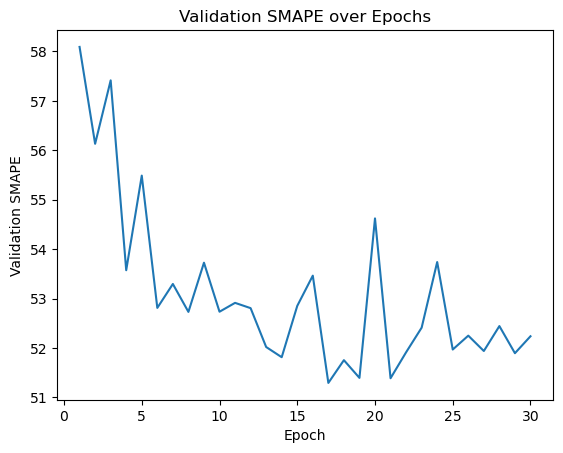

In [ ]:
# fit a simple deep wide MLP model on the same data
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Prepare data
X_train = train_df.drop(columns=["price"]).values
y_train = train_df["price"].values
X_val = val_df.drop(columns=["price"]).values
y_val = val_df["price"].values
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val
, dtype=torch.float32))
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)  

dropout_rate = 0.3
class WideDeepMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        # Deep part
        self.deep = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU()
        )
        # Wide part (linear projection)
        self.wide = nn.Linear(input_dim, 64)
        # Attention over deep features
        self.attn = nn.Sequential(
            nn.Linear(256, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )
        # Final output
        self.out = nn.Linear(256 + 64, 1)
        self.softplus = nn.Softplus()  # ensure positive output

    def forward(self, x):
        deep_feat = self.deep(x)
        wide_feat = self.wide(x)
        attn_weights = self.attn(deep_feat)
        deep_feat = deep_feat * attn_weights
        combined = torch.cat([deep_feat, wide_feat], dim=1)
        return self.softplus(self.out(combined)).squeeze(1)


device = 'cuda' if torch.cuda.is_available() else 'cpu'
input_dim = X_train.shape[1]
model = WideDeepMLP(input_dim).to(device)
criterion = nn.L1Loss()  # MAE loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 30
best_val_mae = float('inf')
smapes = []
for epoch in range(num_epochs):
    model.train()
    train_losses = []
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    
    model.eval()
    val_losses = []
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            val_losses.append(loss.item())
    
    avg_train_loss = np.mean(train_losses)
    avg_val_loss = np.mean(val_losses)
    # calculate SMAPE for val set
    y_val_pred = []
    with torch.no_grad():
        for X_batch, _ in val_loader:
            X_batch = X_batch.to(device)
            y_pred = model(X_batch)
            y_val_pred.extend(y_pred.cpu().numpy())
    val_smape = smape(y_val, np.array(y_val_pred))
    smapes.append(val_smape)    
    print(f"Epoch {epoch+1}/{num_epochs}, Train MAE: {avg_train_loss:.4f}, Val MAE: {avg_val_loss:.4f}, Val SMAPE: {val_smape:.4f}")

    if avg_val_loss < best_val_mae:
        best_val_mae = avg_val_loss
        torch.save(model.state_dict(), "deep_wide_mlp_price_regressor.pth")
        print("💾 Model saved to deep_wide_mlp_price_regressor.pth")
        
plt.plot(range(1, num_epochs+1), smapes)
plt.xlabel("Epoch")
plt.ylabel("Validation SMAPE")
plt.title("Validation SMAPE over Epochs")
plt.show()
